# LiarTree vs ClusTree Evaluation

Reads best-trial results from `param_sweep_results/summary.csv` and plots CMM, F1, purity, and cluster count against noise level, comparing LiarTree and ClusTree on each base dataset.

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("param_sweep_param_disableable_noise_threshold_objective_f1/summary.csv")
print(df)

   algorithm                  dataset     score       cmm        f1  purity  \
0   liartree                 complex9  0.666099  0.686387  0.732766  0.7160   
1   liartree         complex9_noise10  0.155261  0.793718  0.185261  0.5395   
2   liartree         complex9_noise20  0.508126  0.845293  0.568126  0.7240   
3   liartree         complex9_noise30  0.654196  0.864514  0.714196  0.6975   
4   liartree         complex9_noise40  0.190257  0.712724  0.250257  0.3305   
5   liartree         complex9_noise50 -0.113111  0.950867  0.066889  0.5025   
6   liartree          stream_densired -0.094142  0.546658  0.145858  0.3235   
7   liartree  stream_densired_noise10 -0.006485  0.021586  0.020788  0.0170   
8   liartree  stream_densired_noise20  0.120581  0.107043  0.120581  0.0820   
9   liartree  stream_densired_noise30  0.010872  0.021516  0.038145  0.0160   
10  liartree  stream_densired_noise40 -0.193972  0.945830  0.051483  0.3950   
11  liartree  stream_densired_noise50  0.116417  0.9

In [2]:
# Split each dataset name into its base dataset and noise level, e.g.
# "complex9_noise30" -> base="complex9", noise=30; "complex9" -> base="complex9", noise=0.
def split_dataset(name):
    match = re.match(r"^(.*)_noise(\d+)$", name)
    if match:
        return match.group(1), int(match.group(2))
    return name, 0

df[["base_dataset", "noise"]] = df["dataset"].apply(lambda d: pd.Series(split_dataset(d)))
df.sort_values(["base_dataset", "algorithm", "noise"])

,algorithm,dataset,score,cmm,f1,purity,n_clusters,param_lam,param_noise_threshold,param_eps,param_min_samples,base_dataset,noise
12,clustree,complex9,0.862045,0.996986,0.895378,0.9955,10,0.000189,NaN,0.029895,8,complex9,0
13,clustree,complex9_noise10,0.707977,0.929995,0.767977,0.8725,12,0.000021,NaN,0.030745,11,complex9,10
14,clustree,complex9_noise20,0.343701,0.544639,0.403701,0.3285,12,0.491487,NaN,0.026664,4,complex9,20
15,clustree,complex9_noise30,0.503487,0.851923,0.713487,0.6900,17,0.023116,NaN,0.022983,8,complex9,30
16,clustree,complex9_noise40,0.548827,0.746221,0.608827,0.5490,12,0.005539,NaN,0.032868,18,complex9,40
17,clustree,complex9_noise50,0.082170,0.358463,0.142170,0.1885,8,0.451738,NaN,0.033734,8,complex9,50
0,liartree,complex9,0.666099,0.686387,0.732766,0.7160,7,0.000055,1.459262,0.031752,6,complex9,0
1,liartree,complex9_noise10,0.155261,0.793718,0.185261,0.5395,9,0.072750,0.350389,0.010410,1,complex9,10
2,liartree,complex9_noise20,0.508126,0.845293,0.568126,0.7240,12,0.002059,1.355130,0.029596,10,complex9,20
3,liartree,complex9_noise30,0.654196,0.864514,0.714196,0.6975,12,0.193648,1.459918,0.022924,7,complex9,30


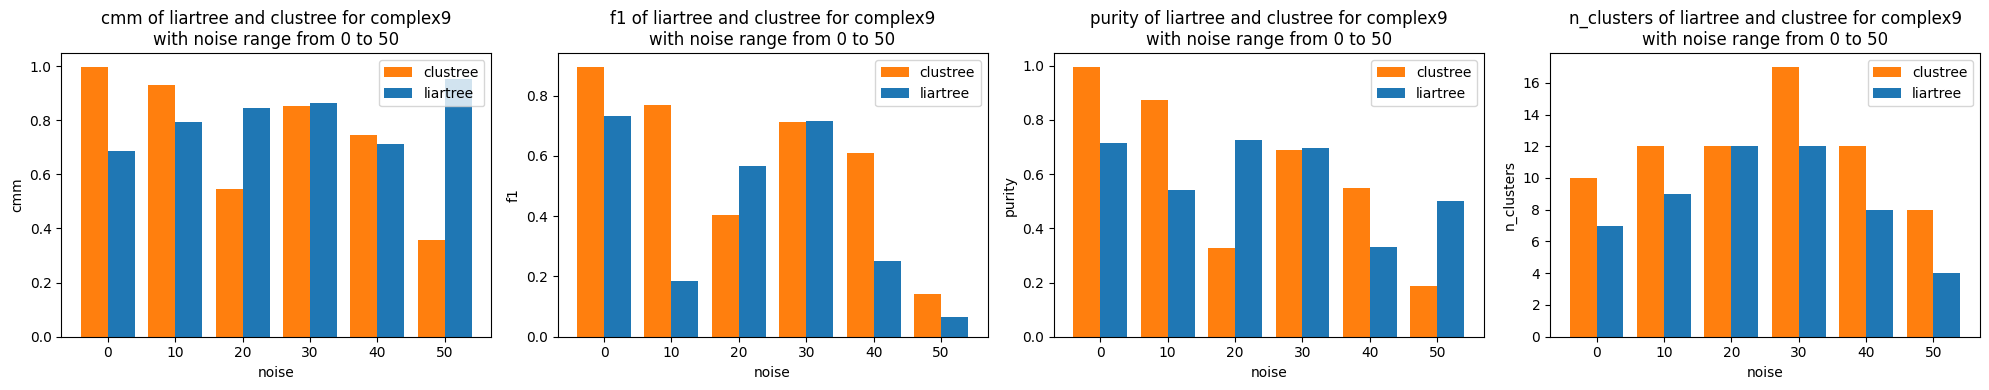

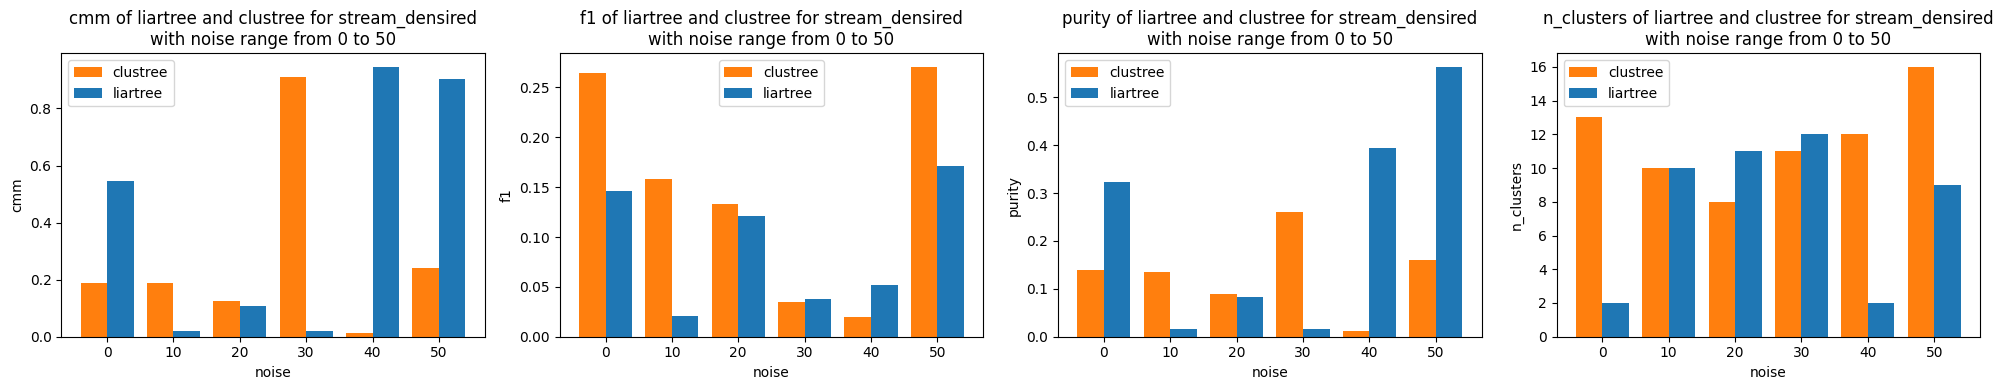

In [3]:
METRICS = ["cmm", "f1", "purity", "n_clusters"]
ALGO_COLORS = {"liartree": "tab:blue", "clustree": "tab:orange"}

base_datasets = sorted(df["base_dataset"].unique())

for dataset in base_datasets:
    sub = df[df["base_dataset"] == dataset]
    noise_min, noise_max = sub["noise"].min(), sub["noise"].max()
    noise_levels = sorted(sub["noise"].unique())
    algorithms = sorted(sub["algorithm"].unique())
    x = list(range(len(noise_levels)))
    width = 0.8 / len(algorithms)

    fig, axes = plt.subplots(1, len(METRICS), figsize=(5 * len(METRICS), 4))
    for ax, metric in zip(axes, METRICS):
        for i, algo in enumerate(algorithms):
            group = sub[sub["algorithm"] == algo].set_index("noise").reindex(noise_levels)
            offsets = [xi + (i + 0.5) * width - 0.4 for xi in x]
            ax.bar(offsets, group[metric], width, label=algo, color=ALGO_COLORS.get(algo))
        ax.set_xticks(x)
        ax.set_xticklabels([f"{n:g}" for n in noise_levels])
        ax.set_xlabel("noise")
        ax.set_ylabel(metric)
        ax.set_title(f"{metric} of liartree and clustree for {dataset}\nwith noise range from {noise_min} to {noise_max}")
        ax.legend()

    fig.tight_layout()
    plt.show()

## Live Stream Visualization

Runs each algorithm over a specified dataset batch-by-batch, live-plotting the leaf micro-clusters and their DBSCAN macro-labels, then plots CMM / purity / cluster-count over time. Structural constructor kwargs mirror `param_sweep.py`'s `BASE_TREE_KWARGS` (the fixed, untuned params); the tuned `lam` / `noise_threshold` / `eps` / `min_samples` are pulled from that algorithm+dataset's best trial in `param_sweep_results/summary.csv` (the `df` loaded above).

Each batch frame is now a two-panel figure: the left panel is the usual micro-cluster scatter plot, and the right panel is a live rendering of the tree itself (`plot_tree_structure`, defined below) -- one box per `Node`, showing every entry's weighted point count `n` and radius `r`, each node's noise buffer (if any), and, for leaf entries, the DBSCAN macro-cluster id (`mc{k}` / `noise`) their micro-cluster was assigned to. That id is colored the same as the corresponding circle in the scatter panel and keyed by the same `e.id` used in `tree.get_summary()`, so a leaf entry in the tree panel can be matched directly to its microcluster in the scatter panel.

Each node's **border color** shows how it was created, via a `created_by` provenance tag set on `Node` at construction time (`src/node.py` / `src/clustree.py` / `src/liartree.py` -- pure metadata, no algorithm behavior changed):
- **green** -- top-down noise-to-cluster growth (`_noise_to_cluster` / `_spawn_liar_root` / `_liar_proc`, Sec. 2.3-2.4): the node is part of a liar subtree grown from a noise buffer that graduated into a cluster.
- **blue** -- bottom-up node-overflow splitting (`ClusTree._split` / `LiarTree._split_liar`): the node was born from an overfull node splitting into two, whether in the main tree or inside a liar subtree.
- **gray** -- the tree's initial root node (neither process).

In [4]:
import sys
sys.path.insert(0, '.')
sys.path.insert(0, 'baseframework')
sys.path.insert(0, 'baseframework/data')
sys.path.insert(0, 'baseframework/metrics')

import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import clear_output

from baseframework import datahandler
from src.liartree import LiarTree
from src.clustree import ClusTree
from src.offline import OfflineClusterer
from cmm import get_cmm

# Structural (untuned) constructor kwargs -- same fixed values param_sweep.py
# uses for every trial (see its BASE_TREE_KWARGS). Only lam / noise_threshold /
# eps / min_samples are tuned per (algorithm, dataset), read below from summary.csv.
BASE_TREE_KWARGS = {
    "liartree": dict(max_fanout=3, leaf_capacity_max=3, descent="depthfirst",
                     budget=10**9, max_height=0, horizon=1000,
                     overlap_reduction=True),
    "clustree": dict(max_fanout=3, leaf_capacity_max=3, descent="depthfirst",
                     budget=10**9, max_height=0, horizon=1000),
}
TREE_CLASSES = {"liartree": LiarTree, "clustree": ClusTree}

_DISTINCT_COLORS = plt.cm.tab20(np.linspace(0, 1, 20))


def get_distinct_color(cluster_id):
    return _DISTINCT_COLORS[cluster_id % len(_DISTINCT_COLORS)]


def compute_purity(y_true, y_pred):
    """Weighted-majority-label purity of a clustering against ground truth."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if len(y_true) == 0:
        return 0.0
    correct = 0
    for label in set(y_pred.tolist()):
        if label == -1:
            continue
        mask = y_pred == label
        if mask.any():
            correct += Counter(y_true[mask].tolist()).most_common(1)[0][1]
    return correct / len(y_true)


def assign_batch_labels(batch, summaries, labels_by_id):
    if len(summaries) == 0:
        return np.full(len(batch), -1)
    mc_ids = list(summaries.keys())
    centers = np.array([summaries[mid]["position"] for mid in mc_ids])
    diffs = batch[:, np.newaxis, :] - centers[np.newaxis, :, :]
    dists = np.sqrt(np.sum(diffs ** 2, axis=2))
    nearest_idx = np.argmin(dists, axis=1)
    return np.array([labels_by_id.get(mc_ids[idx], -1) for idx in nearest_idx])


def best_params(algorithm, dataset):
    """Best-trial params for (algorithm, dataset), as tuned by param_sweep.py
    and recorded in param_sweep_results/summary.csv (the `df` loaded above)."""
    rows = df[(df["algorithm"] == algorithm) & (df["dataset"] == dataset)]
    if rows.empty:
        raise ValueError(f"No summary.csv row for algorithm={algorithm!r}, dataset={dataset!r}")
    return rows.iloc[0]


def run_stream_visualization(algorithm, dataset, batch_size=300, sleep_sec=0.0, cmm_k=5, seed=0,
                             show_tree=False):
    """Stream `dataset` through `algorithm` batch by batch, live-plotting the
    micro-clusters, and return per-batch metric histories. Set show_tree=False
    to skip the tree-structure panel (and its bookkeeping) and just plot the
    scatter panel -- useful when the tree grows large enough that rendering it
    every batch gets slow, or when you only care about the metric history."""
    params = best_params(algorithm, dataset)

    tree_kwargs = dict(BASE_TREE_KWARGS[algorithm])
    tree_kwargs["lam"] = float(params["param_lam"])
    if algorithm == "liartree":
        tree_kwargs["noise_threshold"] = float(params["param_noise_threshold"])
    tree = TREE_CLASSES[algorithm](**tree_kwargs)

    offline = OfflineClusterer(
        method="dbscan", eps=float(params["param_eps"]),
        min_samples=int(params["param_min_samples"]),
        weighted=False, random_state=seed,
    )

    X, y_true = datahandler.load_data(dataset)
    num_batches = len(X) // batch_size + 1

    history = {"batch": [], "cmm": [], "purity": [], "n_clusters": []}

    for i in range(num_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, len(X))
        batch = X[start_idx:end_idx]
        y_batch = y_true[start_idx:end_idx]
        if len(batch) == 0:
            break

        timestamps = np.arange(start_idx, end_idx) + 1
        tree.learn(batch, timestamps)

        summaries = tree.get_summary()
        labels_by_id = offline.predict_summaries(summaries)
        batch_labels = assign_batch_labels(batch, summaries, labels_by_id)

        unique_clusters = set(v for v in labels_by_id.values() if v != -1)
        num_clusters = len(unique_clusters)
        purity = compute_purity(y_batch, batch_labels)

        valid_mask = batch_labels != -1
        if len(set(batch_labels[valid_mask])) >= 2 and valid_mask.sum() >= 10:
            try:
                cmm_val = get_cmm(batch, y_batch, batch_labels, np.ones(len(batch)), cmm_k)
            except Exception:
                cmm_val = float("nan")
        else:
            cmm_val = float("nan")

        history["batch"].append(i + 1)
        history["cmm"].append(cmm_val)
        history["purity"].append(purity)
        history["n_clusters"].append(num_clusters)

        clear_output(wait=True)
        if show_tree:
            fig_w, fig_h, width_ratios = tree_panel_size(tree)
            fig = plt.figure(figsize=(fig_w, fig_h))
            gs = fig.add_gridspec(1, 2, width_ratios=width_ratios)
            ax = fig.add_subplot(gs[0, 0])
            ax_tree = fig.add_subplot(gs[0, 1])
        else:
            fig, ax = plt.subplots(figsize=(10, 8))
            ax_tree = None

        ax.scatter(X[:, 0], X[:, 1], c="whitesmoke", s=10, zorder=0)
        ax.scatter(batch[:, 0], batch[:, 1], c="red", s=15, alpha=0.8, label="New Arrivals", zorder=2)

        for mc_id, mc in summaries.items():
            center, radius = mc["position"], mc["radius"]
            cluster_id = labels_by_id.get(mc_id, -1)
            if cluster_id == -1:
                color, alpha, edge_style = "black", 0.1, "--"
            else:
                color, alpha, edge_style = get_distinct_color(cluster_id), 0.5, "-"
            circle = Circle(center, max(radius, 0.005), linewidth=1, edgecolor="black",
                            linestyle=edge_style, facecolor=color, alpha=alpha, zorder=1)
            ax.add_patch(circle)

        cmm_str = f"{cmm_val:.3f}" if not np.isnan(cmm_val) else "N/A"
        ax.set_title(
            f"{algorithm} Live [{dataset}] - Batch {i+1} | Clusters: {num_clusters} | "
            f"Purity: {purity:.3f} | CMM: {cmm_str} | Microclusters: {len(summaries)}, "
            f"Avg Radius: {tree.avg_leaf_radius():.4f}"
        )
        ax.set_aspect("equal", "box")
        ax.legend(loc="upper right")

        if show_tree:
            plot_tree_structure(tree, ax_tree, labels_by_id)

        fig.tight_layout()
        plt.show()
        if sleep_sec:
            time.sleep(sleep_sec)

    return history


def plot_metric_history(history, algorithm, dataset):
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    axes[0].plot(history["batch"], history["cmm"], color="steelblue", marker="o", markersize=3, linewidth=1.5)
    axes[0].set_ylabel("CMM")
    axes[0].set_title(f"{algorithm} clustering quality metrics over time [{dataset}]")
    axes[0].set_ylim(0, 1)
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history["batch"], history["purity"], color="seagreen", marker="o", markersize=3, linewidth=1.5)
    axes[1].set_ylabel("Purity")
    axes[1].set_ylim(0, 1)
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(history["batch"], history["n_clusters"], color="darkorange", marker="o", markersize=3, linewidth=1.5)
    axes[2].set_ylabel("Cluster Count")
    axes[2].set_xlabel("Batch Step")
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


In [5]:
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D

# ── Tree-structure panel ────────────────────────────────────────────────
#
# Pure read-only inspection of the live tree.Node/Entry/MicroCluster objects
# built by src/liartree.py and src/clustree.py -- no tree logic is touched,
# this just walks the public attributes (node.entries, entry.child,
# entry.summary, node.noise_buffer, node.created_by, ...) that
# _insert_depth_first etc. leave behind after each batch.


def _tree_layout(root):
    """Assign a (x, y) grid position to every Node for plotting: nodes with
    no children (leaf-level, or an empty liar node) get sequential x slots
    left-to-right; inner nodes are centered above their children; y = -depth
    (root at the top). Returns (positions dict keyed by Node, number of
    position-leaf slots used)."""
    positions = {}
    counter = {"n": 0}

    def visit(node, depth):
        children = [e.child for e in node.entries if e.child is not None]
        if not children:
            x = counter["n"]
            counter["n"] += 1
        else:
            xs = [visit(c, depth + 1) for c in children]
            x = sum(xs) / len(xs)
        positions[node] = (x, -depth)
        return x

    visit(root, 0)
    return positions, counter["n"]


def _node_kind(node):
    if node.is_liar_root:
        return "LIAR-ROOT"
    if node.is_liar:
        return "LIAR"
    return "LEAF" if node.is_leaf else "INNER"


def _node_lines(node, tree, labels_by_id):
    """Per-entry text lines for one tree node: weighted point count (n) and
    radius for every entry (Def. 2/3.1), the node's noise buffer if it has
    one (Def. 1), and -- for leaf entries -- the DBSCAN macro-cluster id the
    entry's micro-cluster (keyed by the same e.id used in tree.get_summary())
    was assigned to. That id/color is the same one used for the circles in
    the batch scatter plot, so a leaf entry here can be matched to its
    microcluster there."""
    now = tree._time
    lines = [(_node_kind(node), "black")]
    for idx, e in enumerate(node.entries):
        decayed_n = e.summary.n * 2.0 ** (-tree.lam * (now - e.summary.timestamp))
        radius = e.summary.radius()
        if node.is_leaf:
            cluster_id = labels_by_id.get(e.id, -1) if labels_by_id is not None else -1
            if cluster_id == -1:
                color, tag = "dimgray", "noise"
            else:
                color, tag = get_distinct_color(cluster_id), f"mc{cluster_id}"
            lines.append((f"e{e.id} n={decayed_n:.1f} r={radius:.3f} {tag}", color))
        else:
            buf_n = e.buffer.n if e.buffer is not None else 0.0
            lines.append((f"e{idx} n={decayed_n:.1f} r={radius:.3f} buf={buf_n:.2f}", "black"))

    if node.noise_buffer is not None and not node.noise_buffer.is_empty():
        nb = node.noise_buffer
        nb_n = nb.n * 2.0 ** (-tree.lam * (now - nb.timestamp))
        lines.append((f"noise n={nb_n:.1f} r={nb.radius():.3f}", "firebrick"))

    return lines


# Border color = how the node was created (node.created_by, set at
# construction time in src/node.py / src/clustree.py / src/liartree.py):
#   "noise_to_cluster" -- top-down liar-subtree growth from a graduated
#                         noise buffer (Sec. 2.3-2.4, _noise_to_cluster /
#                         _spawn_liar_root / _liar_proc)
#   "split"             -- bottom-up node-overflow splitting, in the main
#                         tree or inside a liar subtree (ClusTree._split /
#                         LiarTree._split_liar)
#   "root"              -- the tree's initial node (neither process)
_PROVENANCE_COLOR = {"noise_to_cluster": "forestgreen", "split": "royalblue",
                     "root": "dimgray"}
_PROVENANCE_LABEL = {"noise_to_cluster": "noise-to-cluster (top-down)",
                     "split": "overflow split (bottom-up)", "root": "root"}


def plot_tree_structure(tree, ax, labels_by_id=None):
    """Draw the live tree into `ax`: one box per Node (bordered by how the
    node was created -- see _PROVENANCE_COLOR), edges to children, and every
    entry's (n, radius), plus the noise buffer and leaf-entry macro-cluster
    id."""
    positions, _ = _tree_layout(tree.root)

    edges = []
    stack = [tree.root]
    while stack:
        node = stack.pop()
        for e in node.entries:
            if e.child is not None:
                edges.append((node, e.child))
                stack.append(e.child)

    for parent, child in edges:
        x0, y0 = positions[parent]
        x1, y1 = positions[child]
        ax.plot([x0, x1], [y0, y1], color="gray", linewidth=0.8, zorder=0)

    line_h, box_w = 0.20, 0.95
    for node, (x, y) in positions.items():
        lines = _node_lines(node, tree, labels_by_id)
        box_h = len(lines) * line_h + 0.06
        edge_color = _PROVENANCE_COLOR.get(node.created_by, "black")

        rect = FancyBboxPatch((x - box_w / 2, y - box_h / 2), box_w, box_h,
                               boxstyle="round,pad=0.015", linewidth=1.6,
                               edgecolor=edge_color, facecolor="white", zorder=2)
        ax.add_patch(rect)

        top_y = y + box_h / 2 - line_h / 2 - 0.01
        for i, (text, color) in enumerate(lines):
            ax.text(x, top_y - i * line_h, text, ha="center", va="center",
                    fontsize=10, family="monospace", color=color, zorder=3)

    xs = [p[0] for p in positions.values()]
    ys = [p[1] for p in positions.values()]
    ax.set_xlim(min(xs) - 0.7, max(xs) + 0.7)
    ax.set_ylim(min(ys) - 0.7, max(ys) + 0.7)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"Tree structure ({len(positions)} nodes)")

    legend_handles = [
        Line2D([0], [0], color=color, linewidth=2.5, label=_PROVENANCE_LABEL[kind])
        for kind, color in _PROVENANCE_COLOR.items()
    ]
    ax.legend(handles=legend_handles, loc="upper center", fontsize=8,
              bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)


def tree_panel_size(tree, scatter_w_in=10.0, scatter_h_in=8.0,
                     inches_per_leaf=3.1, inches_per_level=2.7):
    """Figure/gridspec sizing so the tree panel's aspect ratio matches its
    own data extent -- otherwise Matplotlib's equal-aspect box would shrink
    it far below the size implied by the width ratio (letterboxing) and the
    per-entry text would overlap between neighboring node boxes."""
    positions, num_leaves = _tree_layout(tree.root)
    depth = int(round(-min(y for _, y in positions.values())))
    tree_w_in = max(5.0, inches_per_leaf * (num_leaves + 1.4))
    tree_h_in = max(4.0, inches_per_level * (depth + 1.4))
    fig_w = scatter_w_in + tree_w_in
    fig_h = max(scatter_h_in, tree_h_in)
    return fig_w, fig_h, [scatter_w_in, tree_w_in]


### LiarTree

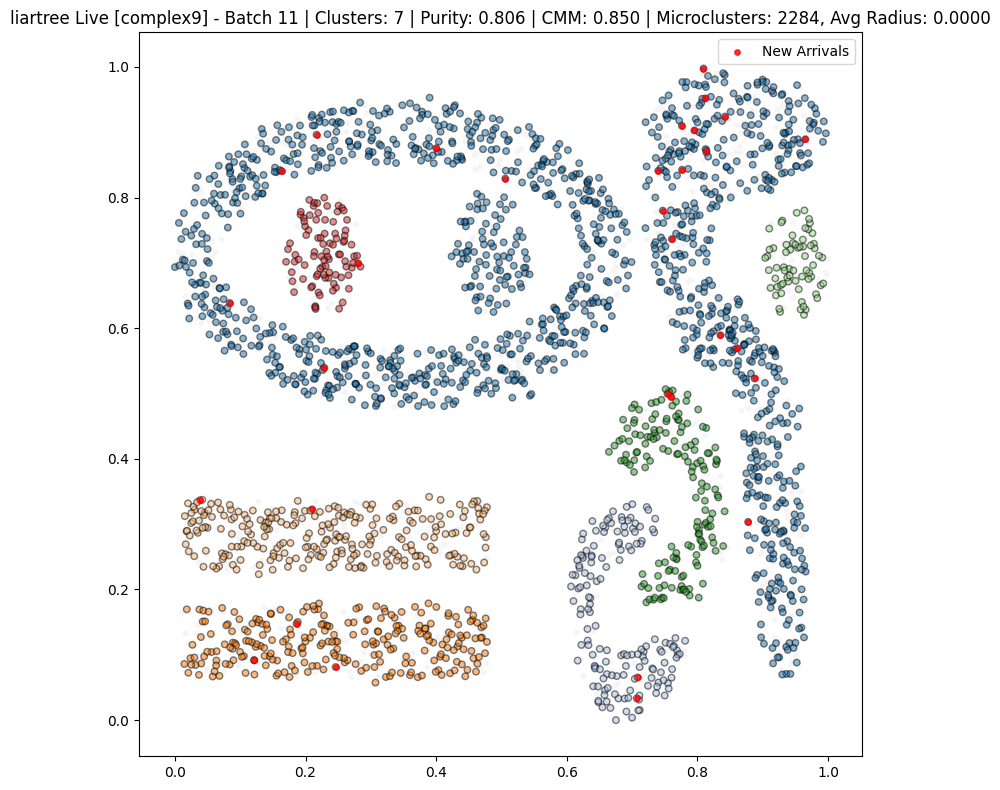

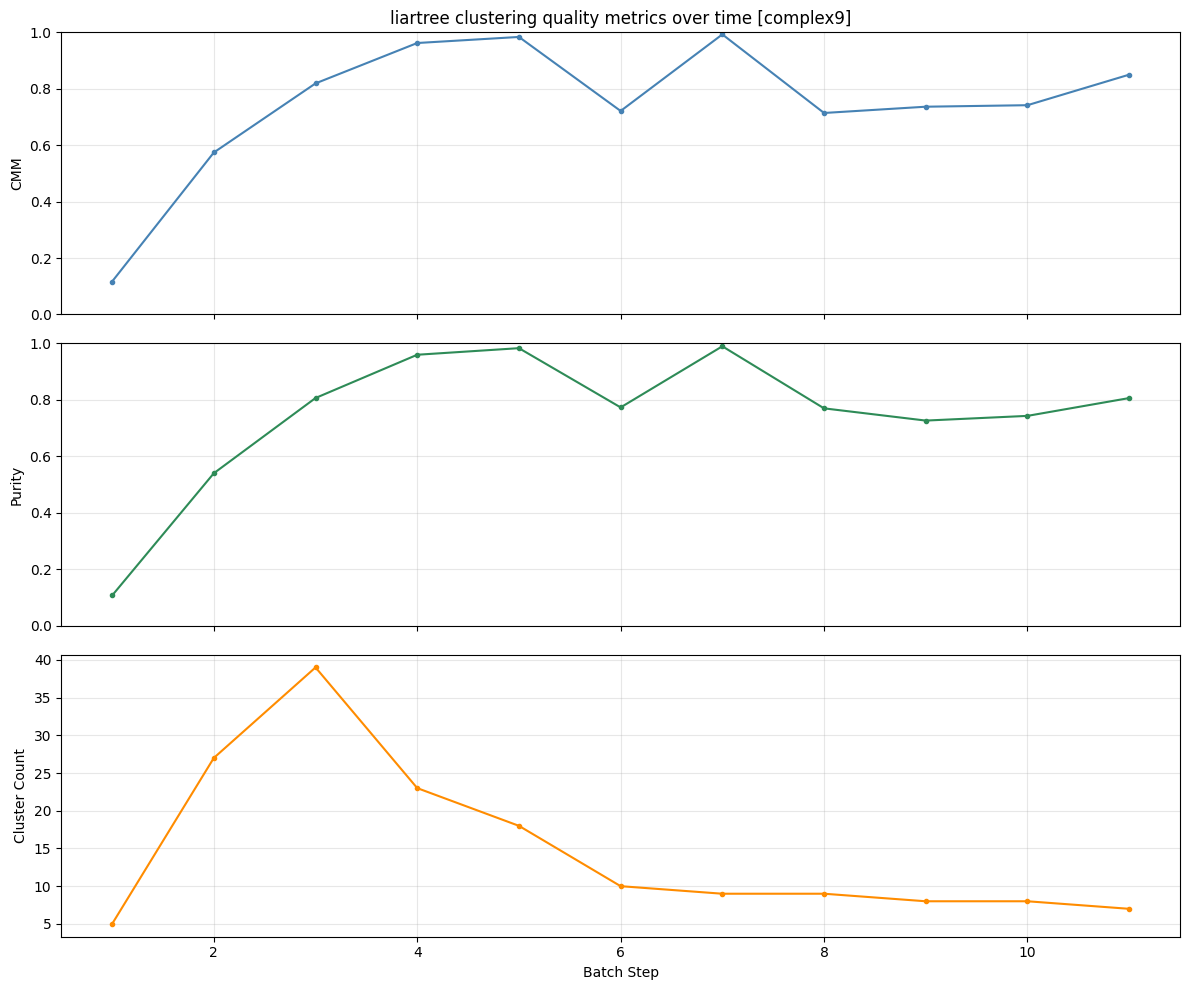

In [28]:
# ── Config ───────────────────────────────────────────────────────────────
DATASET_LT = "complex9"  # choose a dataset to run LiarTree on -- must have a
                          # matching row in param_sweep_results/summary.csv
# ────────────────────────────────────────────────────────────────────────

lt_history = run_stream_visualization("liartree", DATASET_LT, batch_size=300, sleep_sec=1)
plot_metric_history(lt_history, "liartree", DATASET_LT)

### ClusTree

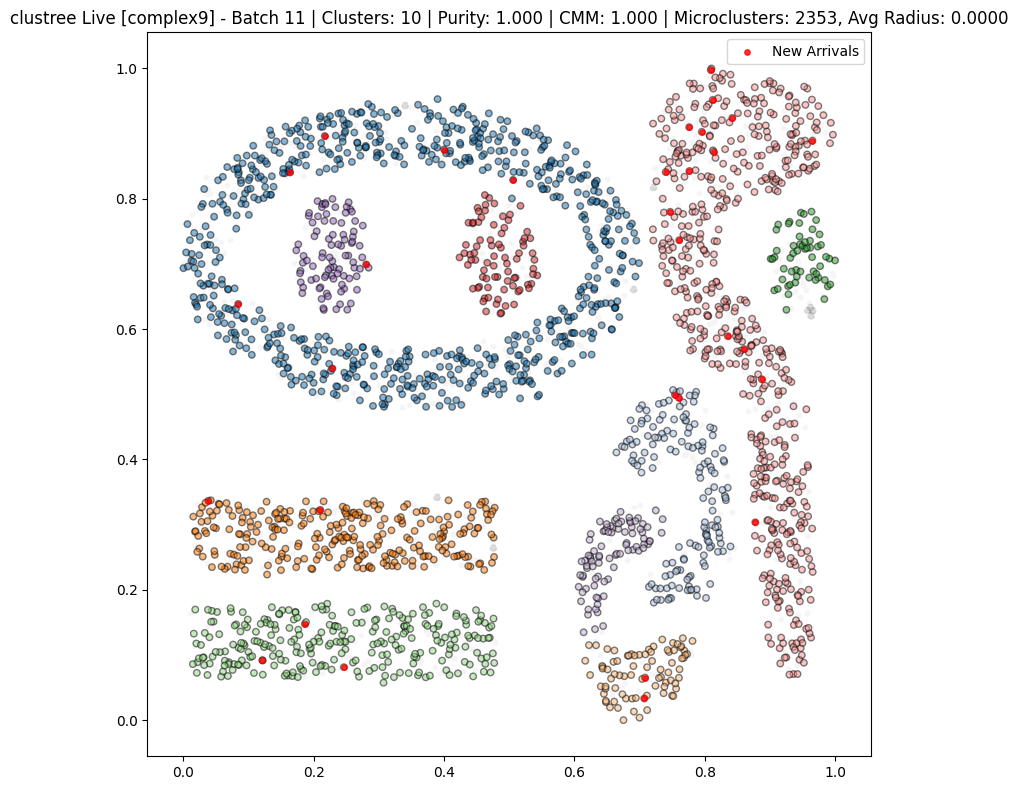

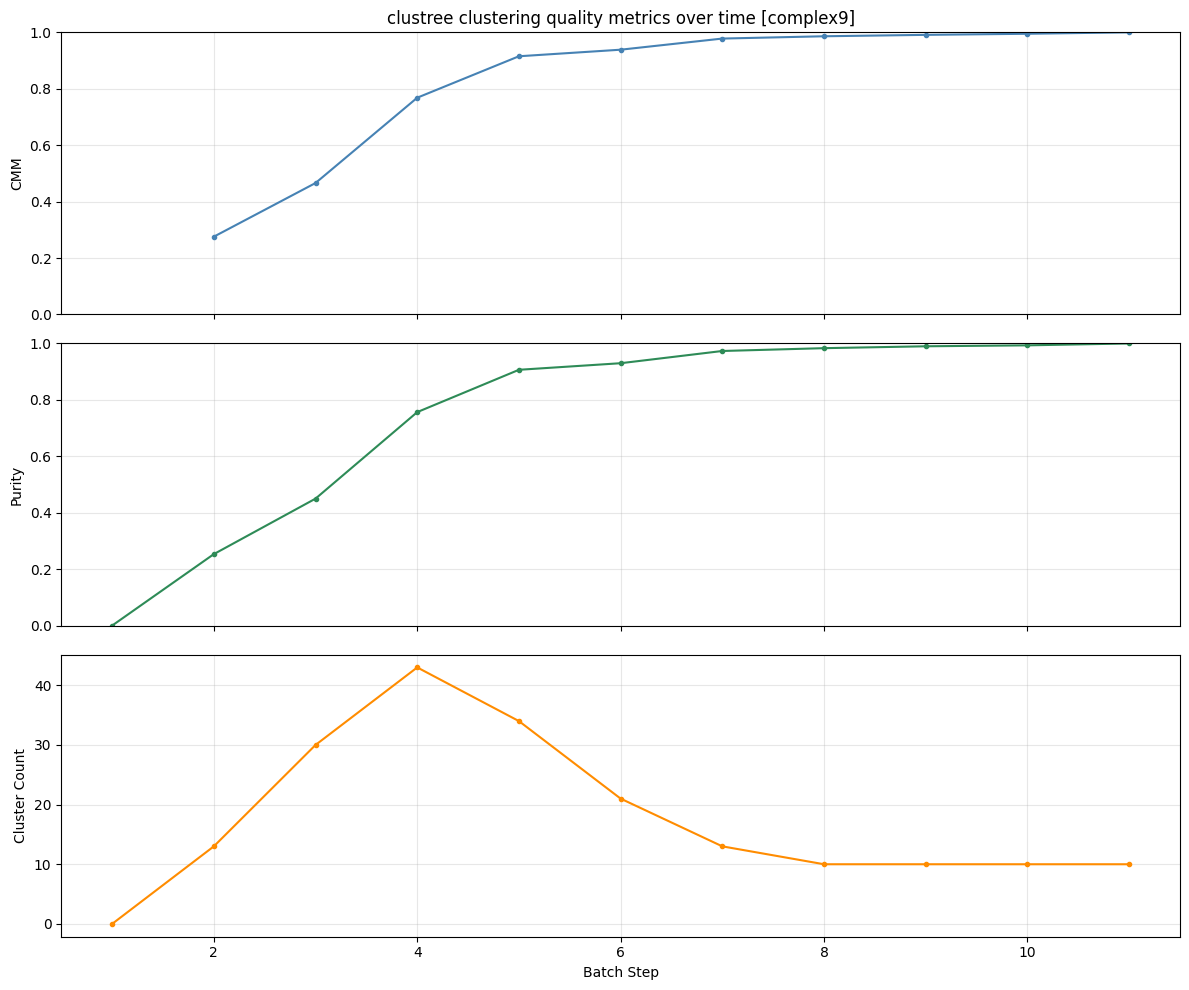

In [7]:
# ── Config ───────────────────────────────────────────────────────────────
DATASET_CT = "complex9"  # choose a dataset to run ClusTree on -- must have a
                          # matching row in param_sweep_results/summary.csv
# ────────────────────────────────────────────────────────────────────────

ct_history = run_stream_visualization("clustree", DATASET_CT, show_tree=False)
plot_metric_history(ct_history, "clustree", DATASET_CT)


## Data Burst Experiment (Sinusoidal Budget)

Mimics a bursty arrival rate by driving each tree's anytime `budget` (max distance computations per insertion, see the `budget` docstring in `src/clustree.py`) with a sinusoidal schedule instead of holding it constant -- the same idea `rate_sweep.py` already sweeps over the CLI:

    rate(i)   = 1 + magnitude * sin(2*pi*frequency*i/n)
    budget(i) = clip(round(base_budget / rate(i)), budget_min, budget_max)

High instantaneous rate -> less time available per point -> lower budget; low rate -> higher budget.

**Feasibility check**: this only requires reassigning `tree.budget` between `learn_one` calls -- no change to `src/clustree.py` / `src/liartree.py`. `ClusTree.learn_one` re-reads `self.budget` fresh at the top of every call (`self._cur_budget = self.budget`), so a new value takes effect on the very next insertion. `rate_sweep.py` already relies on exactly this pattern outside a notebook, so it's proven to work; the block below reuses its `sinusoidal_budget_schedule` function directly instead of reimplementing it.

Pick one dataset below (shared by both algorithms so they're directly comparable), then run each algorithm over two sweeps -- (a) magnitude at a fixed frequency, (b) frequency at a fixed magnitude. The comparison plots at the end are grouped bar charts of final-of-stream F1 and CMM (the same quality metrics `param_sweep.py`'s objective is built from) against the swept value, with LiarTree and ClusTree bars side by side. `lam` / `noise_threshold` / `eps` / `min_samples` are the same tuned params used by the "optimal param" block above (`best_params` / `df`) -- only the budget schedule changes here.

In [8]:
from rate_sweep import sinusoidal_budget_schedule, DEFAULT_BASE_BUDGET
from param_sweep import _compute_f1


def run_burst_experiment(algorithm, dataset, axis, values, frequency_fixed, magnitude_fixed,
                         base_budget, snapshot_every_frac=0.02, max_eval_n=2000,
                         budget_min=1, budget_max_multiplier=5.0, seed=0):
    """Stream `dataset` through `algorithm` once per value in `values`, driving
    the anytime budget with a sinusoidal schedule instead of a constant one to
    mimic a bursty arrival rate. `axis` selects whether `values` sweeps
    magnitude or frequency; the other one is held at its `_fixed` value.
    Returns {value: per-snapshot DataFrame(step, budget, rate, n_microclusters,
    n_clusters, f1, cmm)}.

    lam/noise_threshold/eps/min_samples come from best_params(algorithm,
    dataset) (the tuned params loaded into `df` above) -- only tree.budget is
    reassigned per step below, nothing about the tree constructors changes.
    """
    params = best_params(algorithm, dataset)
    tree_kwargs = dict(BASE_TREE_KWARGS[algorithm])
    tree_kwargs["lam"] = float(params["param_lam"])
    if algorithm == "liartree":
        tree_kwargs["noise_threshold"] = float(params["param_noise_threshold"])

    offline = OfflineClusterer(
        method="dbscan", eps=float(params["param_eps"]),
        min_samples=int(params["param_min_samples"]),
        weighted=False, random_state=seed,
    )

    X, y_true = datahandler.load_data(dataset)
    n = len(X)
    rng = np.random.default_rng(seed)
    cap = min(max_eval_n, n)
    eval_idx_full = np.sort(rng.choice(n, size=cap, replace=False)) if cap < n else np.arange(n)

    snapshot_every = max(1, int(round(n * snapshot_every_frac)))
    budget_max = base_budget * budget_max_multiplier

    results = {}
    for value in values:
        magnitude = value if axis == "magnitude" else magnitude_fixed
        frequency = frequency_fixed if axis == "magnitude" else value
        schedule, rate = sinusoidal_budget_schedule(
            n, base_budget, magnitude, frequency, budget_min, budget_max)

        tree_kwargs_run = dict(tree_kwargs)
        tree_kwargs_run["budget"] = int(schedule[0])
        tree = TREE_CLASSES[algorithm](**tree_kwargs_run)

        rows = []
        for i in range(n):
            tree.budget = int(schedule[i])   # <- the only "burst" hook; learn_one
            tree.learn_one(X[i], t=i + 1)    #    re-reads self.budget every call
            n_seen = i + 1
            if n_seen % snapshot_every != 0 and n_seen != n:
                continue

            summaries = tree.get_summary()
            idx = eval_idx_full[eval_idx_full < n_seen]
            row = dict(step=n_seen, budget=int(schedule[i]), rate=float(rate[i]),
                      n_microclusters=len(summaries))
            if not summaries or len(idx) == 0:
                row.update(n_clusters=0, f1=np.nan, cmm=np.nan)
            else:
                labels_by_id = offline.predict_summaries(summaries)
                X_eval, y_eval = X[idx], y_true[idx]
                pred = assign_batch_labels(X_eval, summaries, labels_by_id)
                n_clusters = len(set(pred.tolist()) - {-1})
                row["n_clusters"] = n_clusters
                if n_clusters >= 1:
                    row["f1"] = _compute_f1(y_eval, pred, X_eval)
                    try:
                        row["cmm"] = float(get_cmm(X_eval, y_eval, pred, np.ones(len(idx)), 5))
                    except Exception:
                        row["cmm"] = np.nan
                else:
                    row["f1"] = np.nan
                    row["cmm"] = np.nan
            rows.append(row)

        results[value] = pd.DataFrame(rows)
    return results


def plot_burst_bar(results_by_algo, axis, dataset, fixed_value, metric):
    """Grouped bar chart comparing algorithms on one sweep axis: x = swept
    value, y = final-of-stream `metric` (last snapshot of each run), one bar
    per algorithm per value. `results_by_algo` is {algorithm: {value:
    per-snapshot DataFrame}} as returned by run_burst_experiment, one entry
    per algorithm run over the same swept values and dataset."""
    fixed_name = "frequency" if axis == "magnitude" else "magnitude"
    algorithms = list(results_by_algo)
    values = sorted(next(iter(results_by_algo.values())).keys())

    x = np.arange(len(values))
    width = 0.8 / len(algorithms)

    fig, ax = plt.subplots(figsize=(8, 5))
    for i, algo in enumerate(algorithms):
        heights = [results_by_algo[algo][v][metric].iloc[-1] for v in values]
        ax.bar(x + (i + 0.5) * width - 0.4, heights, width,
              label=algo, color=ALGO_COLORS.get(algo))

    ax.set_xticks(x)
    ax.set_xticklabels([f"{v:g}" for v in values])
    ax.set_xlabel(axis)
    ax.set_ylabel(f"final {metric}")
    ax.set_ylim(0, 1)
    ax.set_title(f"[{dataset}] data burst: final {metric} vs. {axis}\n"
                f"fixed {fixed_name}={fixed_value:g}")
    ax.legend(title="algorithm")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

/mnt/c/Users/jjack/Repos/stream-clustering/liartree/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Config

In [9]:
# ── Config (shared by both algorithms, so they're directly comparable) ────
DATASET_BURST = "complex9"  # must have a matching row in the summary.csv loaded as `df` above
BASE_BUDGET = DEFAULT_BASE_BUDGET.get(DATASET_BURST, 20)  # rate_sweep.py's
                                # calibrated per-dataset value if available,
                                # else a generic fallback -- override manually
                                # if the sinusoid never binds or always saturates

FREQUENCY_FIXED = 3.0                        # cycles over the stream, held fixed for the magnitude sweep
MAGNITUDES = [0.0, 0.2, 0.4, 0.6, 0.8]       # swept at FREQUENCY_FIXED

MAGNITUDE_FIXED = 0.6                    # held fixed for the frequency sweep
FREQUENCIES = [0.5, 1, 2, 5, 10, 20, 50]  # swept at MAGNITUDE_FIXED
# ────────────────────────────────────────────────────────────────────────

### LiarTree

In [10]:
lt_mag_results = run_burst_experiment("liartree", DATASET_BURST, "magnitude",
                                      MAGNITUDES, FREQUENCY_FIXED, MAGNITUDE_FIXED,
                                      BASE_BUDGET)
lt_freq_results = run_burst_experiment("liartree", DATASET_BURST, "frequency",
                                       FREQUENCIES, FREQUENCY_FIXED, MAGNITUDE_FIXED,
                                       BASE_BUDGET)

### ClusTree

In [11]:
ct_mag_results = run_burst_experiment("clustree", DATASET_BURST, "magnitude",
                                      MAGNITUDES, FREQUENCY_FIXED, MAGNITUDE_FIXED,
                                      BASE_BUDGET)
ct_freq_results = run_burst_experiment("clustree", DATASET_BURST, "frequency",
                                       FREQUENCIES, FREQUENCY_FIXED, MAGNITUDE_FIXED,
                                       BASE_BUDGET)

### Comparison plots

Both algorithms, same dataset, one bar chart per (swept axis, metric) combo -- LiarTree and ClusTree side by side.

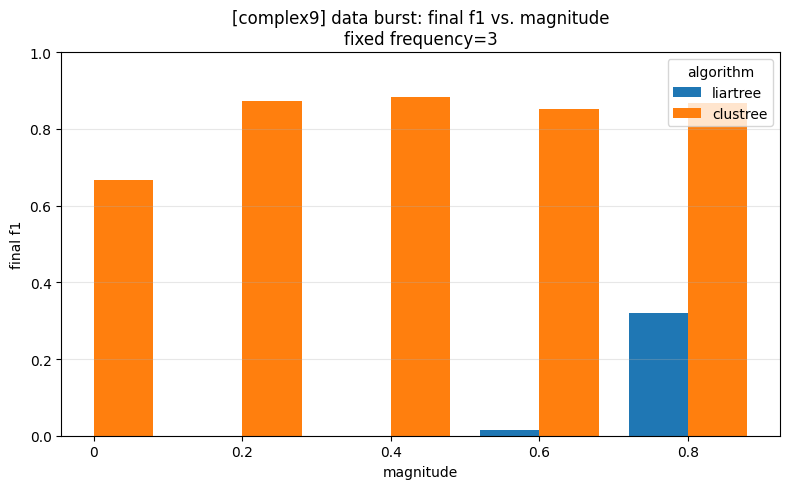

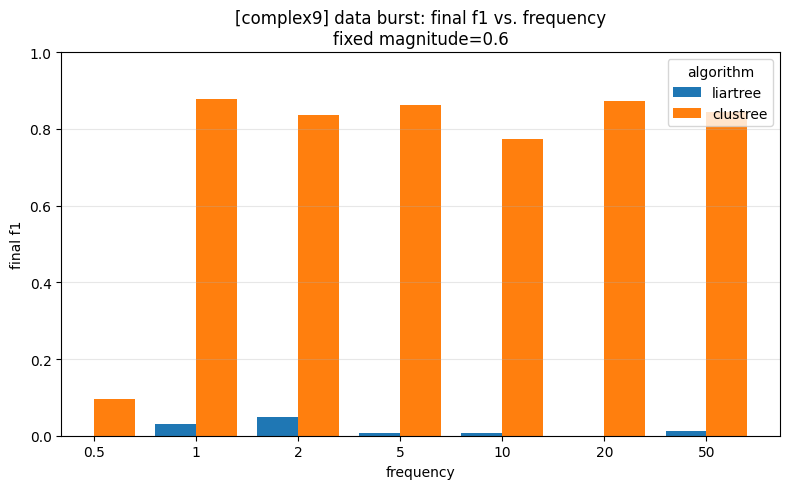

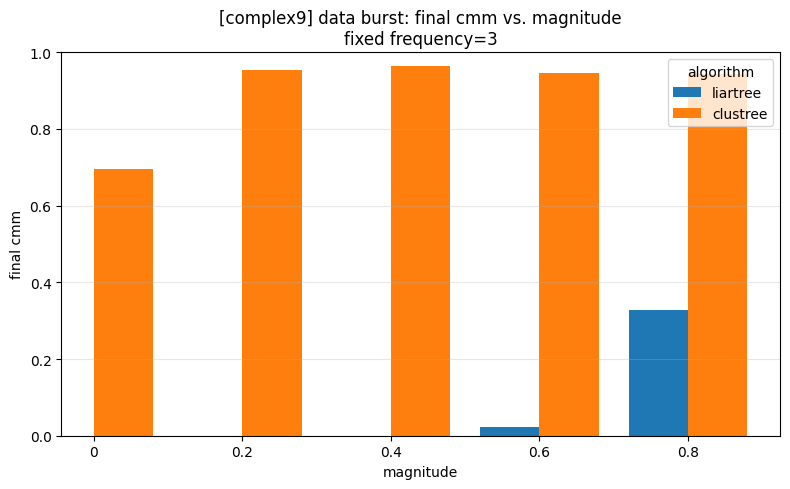

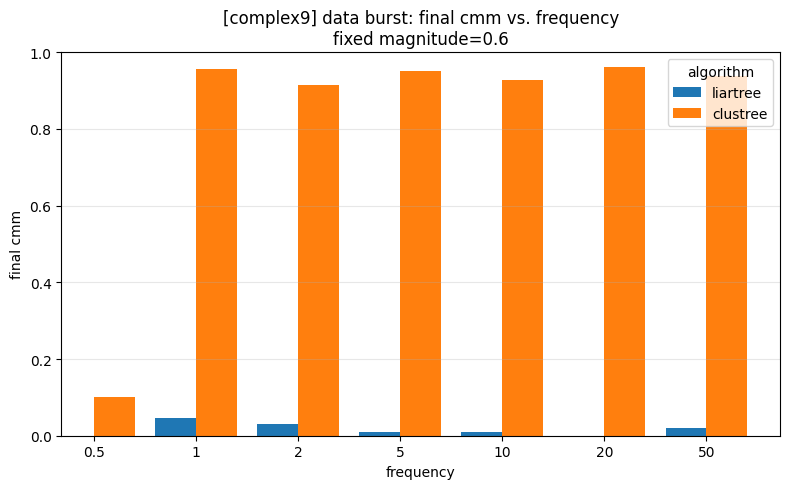

In [12]:
mag_results_by_algo = {"liartree": lt_mag_results, "clustree": ct_mag_results}
freq_results_by_algo = {"liartree": lt_freq_results, "clustree": ct_freq_results}

for metric in ("f1", "cmm"):
    plot_burst_bar(mag_results_by_algo, "magnitude", DATASET_BURST, FREQUENCY_FIXED, metric)
    plot_burst_bar(freq_results_by_algo, "frequency", DATASET_BURST, MAGNITUDE_FIXED, metric)

## Microcluster Count Growth Over Time

Reuses the `frequency=FREQUENCY_FIXED`, `magnitude=MAGNITUDE_FIXED` runs already computed in
`lt_mag_results` / `ct_mag_results` above (the magnitude sweep includes `MAGNITUDE_FIXED` at
`FREQUENCY_FIXED`) to plot how each algorithm's microcluster count grows over time, LiarTree and
ClusTree together in one figure. The driving budget schedule (identical for both algorithms --
it depends only on dataset length / frequency / magnitude, not the tree) is drawn on a secondary
right y-axis, since microcluster count and budget live on very different scales.

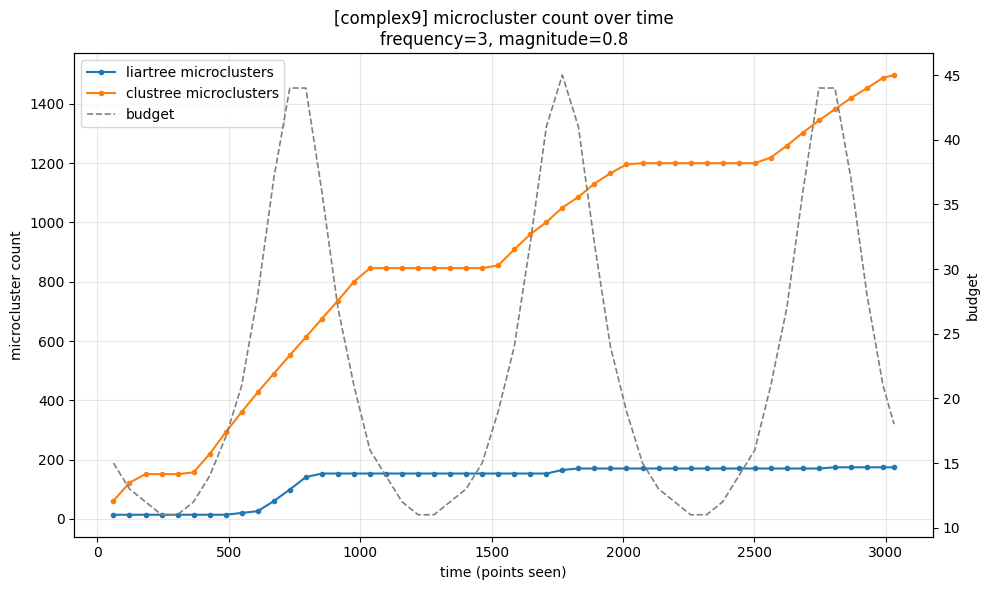

In [25]:
growth_results = {
    "liartree": lt_mag_results[MAGNITUDE_FIXED],
    "clustree": ct_mag_results[MAGNITUDE_FIXED],
}


def plot_microcluster_growth(results_by_algo, dataset, frequency, magnitude):
    """Microcluster count over time for each algorithm (left y-axis), plus the
    driving budget schedule (right y-axis) -- separate scales since budget and
    microcluster count differ by orders of magnitude."""
    fig, ax = plt.subplots(figsize=(10, 6))
    ax_budget = ax.twinx()

    for algo, hist in results_by_algo.items():
        ax.plot(hist["step"], hist["n_microclusters"], marker="o", markersize=3,
                linewidth=1.5, color=ALGO_COLORS.get(algo), label=f"{algo} microclusters")

    budget_ref = next(iter(results_by_algo.values()))
    ax_budget.plot(budget_ref["step"], budget_ref["budget"], color="gray", linestyle="--",
                  linewidth=1.2, label="budget")

    ax.set_xlabel("time (points seen)")
    ax.set_ylabel("microcluster count")
    ax_budget.set_ylabel("budget")
    ax.set_title(f"[{dataset}] microcluster count over time\nfrequency={frequency:g}, magnitude={magnitude:g}")
    ax.grid(True, alpha=0.3)

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax_budget.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

    fig.tight_layout()
    plt.show()

FREQUENCY_LT = 3.0   # cycles of the sinusoidal rate over the whole stream
MAGNITUDE_LT = 0.8   # amplitude of the rate oscillation, in [0, 1)
plot_microcluster_growth(growth_results, DATASET_BURST, FREQUENCY_LT, MAGNITUDE_LT)

## Bursty Live Stream Visualization (Custom Frequency / Magnitude / Hyperparams)

Combines the live scatter + tree-structure panel from **Live Stream Visualization** above with the sinusoidal bursty-arrival budget schedule from **Data Burst Experiment** below: `rate(i) = 1 + magnitude*sin(2*pi*frequency*i/n)`, `budget(i) = clip(round(base_budget/rate(i)), budget_min, budget_max)` (`sinusoidal_budget_schedule`, imported above). Unlike `run_stream_visualization`, which holds `tree.budget` fixed, `tree.budget` is reassigned every single point here so the anytime budget genuinely oscillates within each plotted batch, not just across batches.

Pick `frequency` / `magnitude` yourself (see the "Data Burst Experiment" section above for what makes a value too small/large for a given dataset's length: too high a `frequency` aliases against the plotted batch size, too high a `magnitude` saturates against `budget_max`). `lam` / `noise_threshold` / `eps` / `min_samples` / `base_budget` default to that algorithm+dataset's tuned best trial (`best_params`, from `summary.csv`) and `DEFAULT_BASE_BUDGET`, same fallback `run_burst_experiment` uses -- pass any of them explicitly to override.


In [13]:
def run_burst_stream_visualization(algorithm, dataset, frequency, magnitude,
                                   base_budget=None, lam=None, noise_threshold=None,
                                   eps=None, min_samples=None, batch_size=300,
                                   sleep_sec=0.0, cmm_k=5, seed=0, show_tree=False,
                                   budget_min=1, budget_max_multiplier=5.0):
    """Live scatter + tree-structure visualization (as `run_stream_visualization`
    above), but drives `tree.budget` with the sinusoidal bursty-arrival schedule
    from `run_burst_experiment` instead of holding it constant. `frequency` /
    `magnitude` are required (that's the point of this block); any of
    `lam` / `noise_threshold` / `eps` / `min_samples` / `base_budget` left as
    None falls back to `best_params(algorithm, dataset)` / `DEFAULT_BASE_BUDGET`,
    same tuned defaults `run_burst_experiment` uses. Returns the same
    {batch, cmm, purity, n_clusters} history dict `run_stream_visualization`
    does (plus `budget` / `rate`), so it's a drop-in for `plot_metric_history`.
    """
    params = best_params(algorithm, dataset)
    lam = float(lam) if lam is not None else float(params["param_lam"])
    eps = float(eps) if eps is not None else float(params["param_eps"])
    min_samples = int(min_samples) if min_samples is not None else int(params["param_min_samples"])

    tree_kwargs = dict(BASE_TREE_KWARGS[algorithm])
    tree_kwargs["lam"] = lam
    if algorithm == "liartree":
        noise_threshold = (float(noise_threshold) if noise_threshold is not None
                           else float(params["param_noise_threshold"]))
        tree_kwargs["noise_threshold"] = noise_threshold

    if base_budget is None:
        base_budget = DEFAULT_BASE_BUDGET.get(dataset, 20)

    offline = OfflineClusterer(method="dbscan", eps=eps, min_samples=min_samples,
                               weighted=False, random_state=seed)

    X, y_true = datahandler.load_data(dataset)
    n = len(X)
    budget_max = base_budget * budget_max_multiplier
    schedule, rate = sinusoidal_budget_schedule(
        n, base_budget, magnitude, frequency, budget_min, budget_max)

    tree_kwargs["budget"] = int(schedule[0])
    tree = TREE_CLASSES[algorithm](**tree_kwargs)

    num_batches = n // batch_size + 1
    history = {"batch": [], "cmm": [], "purity": [], "n_clusters": [], "budget": [], "rate": []}

    for i in range(num_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, n)
        batch = X[start_idx:end_idx]
        y_batch = y_true[start_idx:end_idx]
        if len(batch) == 0:
            break

        # Unlike run_stream_visualization's tree.learn(batch, timestamps), budget
        # must be reassigned before every single point -- learn_one re-reads
        # self.budget fresh at the top of each call (see the "Data Burst
        # Experiment" cell above), so a batched tree.learn() call would freeze
        # it at whatever it was when the batch started.
        for j, x in enumerate(batch):
            idx = start_idx + j
            tree.budget = int(schedule[idx])
            tree.learn_one(x, t=idx + 1)

        summaries = tree.get_summary()
        labels_by_id = offline.predict_summaries(summaries)
        batch_labels = assign_batch_labels(batch, summaries, labels_by_id)

        unique_clusters = set(v for v in labels_by_id.values() if v != -1)
        num_clusters = len(unique_clusters)
        purity = compute_purity(y_batch, batch_labels)

        valid_mask = batch_labels != -1
        if len(set(batch_labels[valid_mask])) >= 2 and valid_mask.sum() >= 10:
            try:
                cmm_val = get_cmm(batch, y_batch, batch_labels, np.ones(len(batch)), cmm_k)
            except Exception:
                cmm_val = float("nan")
        else:
            cmm_val = float("nan")

        cur_budget, cur_rate = int(schedule[end_idx - 1]), float(rate[end_idx - 1])

        history["batch"].append(i + 1)
        history["cmm"].append(cmm_val)
        history["purity"].append(purity)
        history["n_clusters"].append(num_clusters)
        history["budget"].append(cur_budget)
        history["rate"].append(cur_rate)

        clear_output(wait=True)
        if show_tree:
            fig_w, fig_h, width_ratios = tree_panel_size(tree)
            fig = plt.figure(figsize=(fig_w, fig_h))
            gs = fig.add_gridspec(1, 2, width_ratios=width_ratios)
            ax = fig.add_subplot(gs[0, 0])
            ax_tree = fig.add_subplot(gs[0, 1])
        else:
            fig, ax = plt.subplots(figsize=(10, 8))
            ax_tree = None

        ax.scatter(X[:, 0], X[:, 1], c="whitesmoke", s=10, zorder=0)
        ax.scatter(batch[:, 0], batch[:, 1], c="red", s=15, alpha=0.8, label="New Arrivals", zorder=2)

        for mc_id, mc in summaries.items():
            center, radius = mc["position"], mc["radius"]
            cluster_id = labels_by_id.get(mc_id, -1)
            if cluster_id == -1:
                color, alpha, edge_style = "black", 0.1, "--"
            else:
                color, alpha, edge_style = get_distinct_color(cluster_id), 0.5, "-"
            circle = Circle(center, max(radius, 0.005), linewidth=1, edgecolor="black",
                            linestyle=edge_style, facecolor=color, alpha=alpha, zorder=1)
            ax.add_patch(circle)

        cmm_str = f"{cmm_val:.3f}" if not np.isnan(cmm_val) else "N/A"
        ax.set_title(
            f"{algorithm} Burst [{dataset}] freq={frequency:g} mag={magnitude:g} - Batch {i+1} | "
            f"budget={cur_budget} (rate={cur_rate:.2f}) | Clusters: {num_clusters} | "
            f"Purity: {purity:.3f} | CMM: {cmm_str} | Microclusters: {len(summaries)}"
        )
        ax.set_aspect("equal", "box")
        ax.legend(loc="upper right")

        if show_tree:
            plot_tree_structure(tree, ax_tree, labels_by_id)

        fig.tight_layout()
        plt.show()
        if sleep_sec:
            time.sleep(sleep_sec)

    return history


### LiarTree


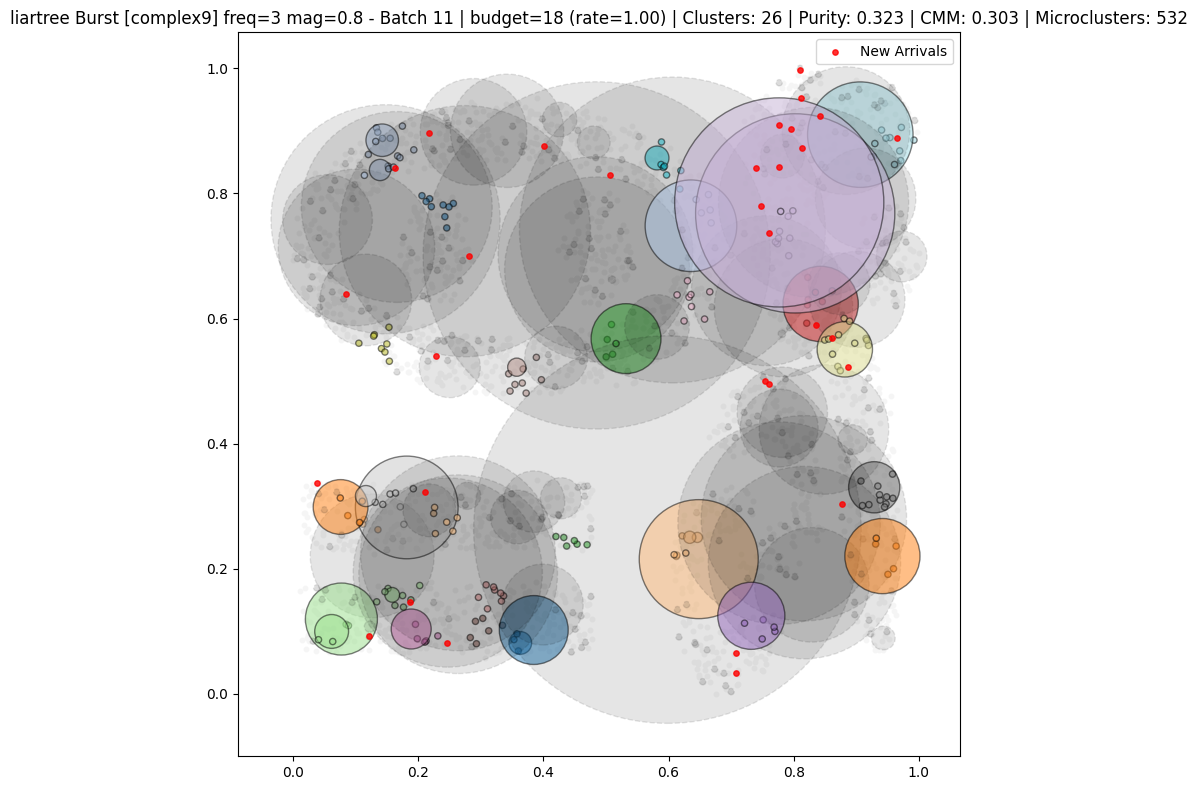

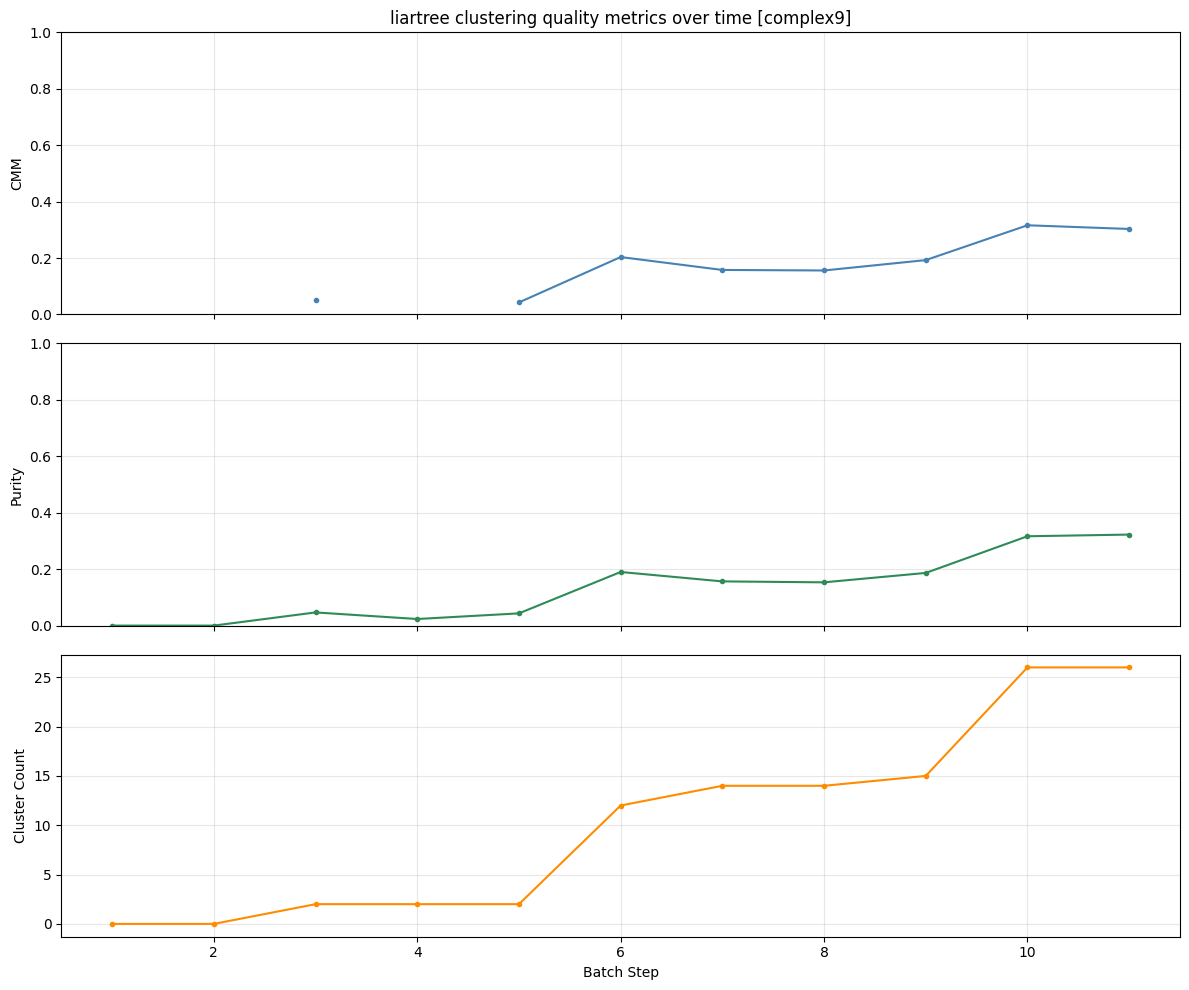

In [23]:
# ── Config ───────────────────────────────────────────────────────────────
DATASET_BURST_VIZ_LT = "complex9"  # must have a matching row in summary.csv
FREQUENCY_LT = 3.0   # cycles of the sinusoidal rate over the whole stream
MAGNITUDE_LT = 0.8   # amplitude of the rate oscillation, in [0, 1)

# Leave any of these as None to use that algorithm+dataset's tuned best
# trial (lam/noise_threshold/eps/min_samples) or calibrated default
# (base_budget) instead of overriding it here.
BASE_BUDGET_LT = None
LAM_LT = None
NOISE_THRESHOLD_LT = None
EPS_LT = None
MIN_SAMPLES_LT = None
# ────────────────────────────────────────────────────────────────────────

lt_burst_history = run_burst_stream_visualization(
    "liartree", DATASET_BURST_VIZ_LT, FREQUENCY_LT, MAGNITUDE_LT,
    base_budget=BASE_BUDGET_LT, lam=LAM_LT, noise_threshold=NOISE_THRESHOLD_LT,
    eps=EPS_LT, min_samples=MIN_SAMPLES_LT, batch_size=300, sleep_sec=1, show_tree=False,
)
plot_metric_history(lt_burst_history, "liartree", DATASET_BURST_VIZ_LT)


### ClusTree


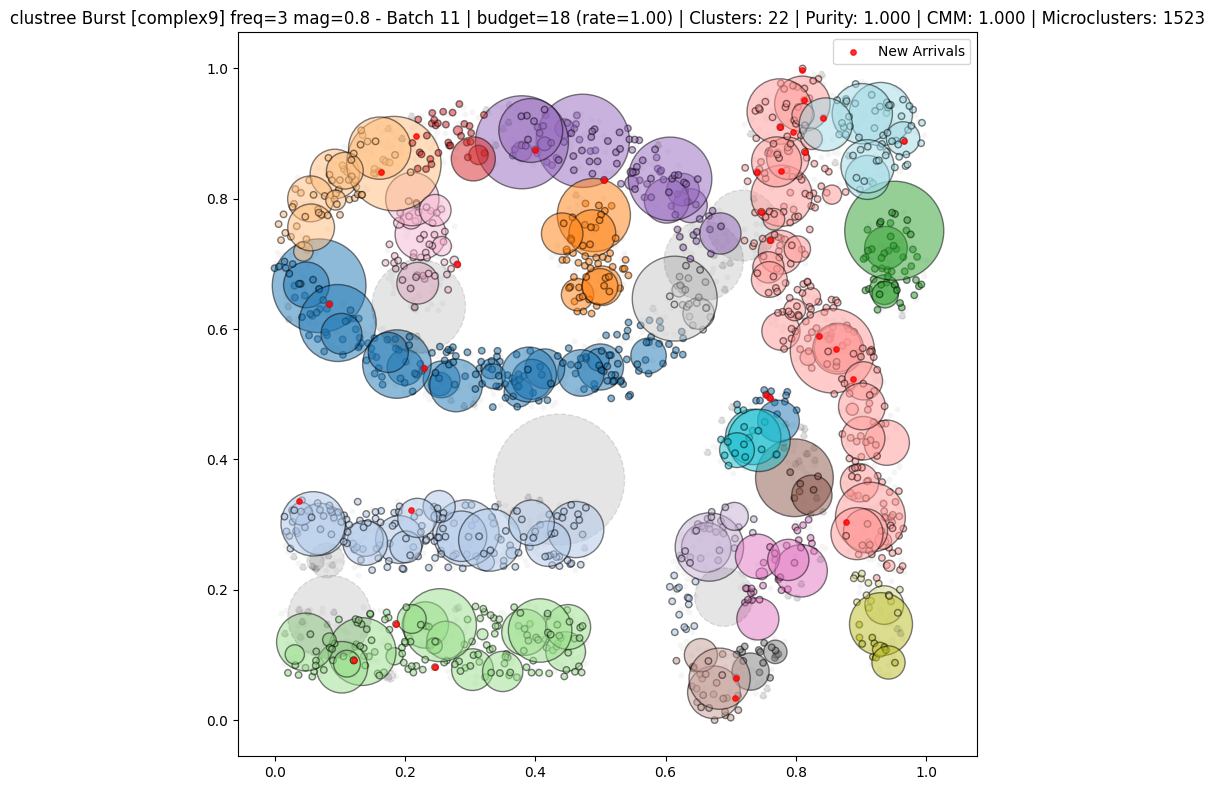

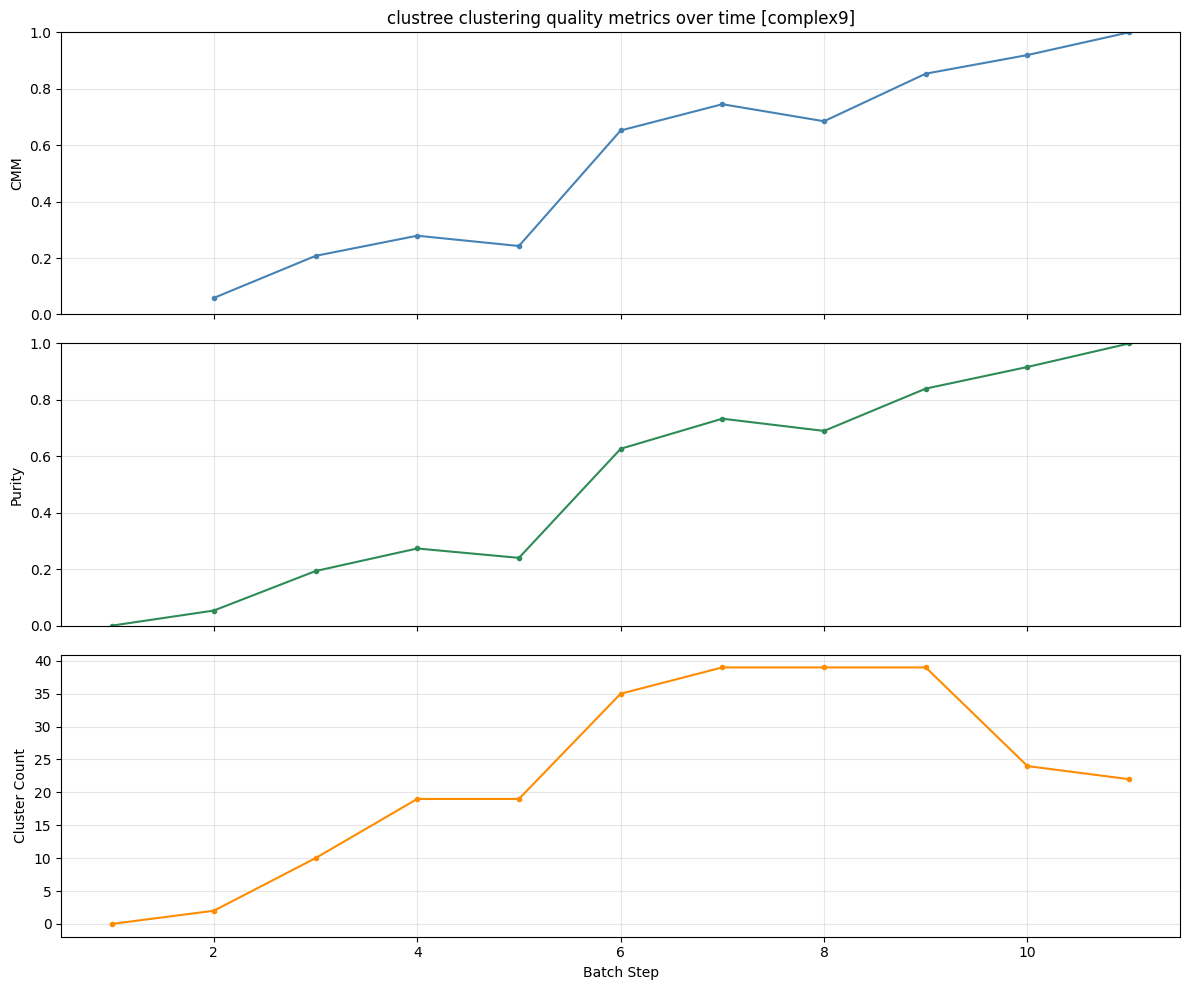

In [20]:
# ── Config ───────────────────────────────────────────────────────────────
DATASET_BURST_VIZ_CT = "complex9"  # must have a matching row in summary.csv
FREQUENCY_CT = 3.0   # cycles of the sinusoidal rate over the whole stream
MAGNITUDE_CT = 0.8   # amplitude of the rate oscillation, in [0, 1)

# Leave any of these as None to use that algorithm+dataset's tuned best
# trial (lam/eps/min_samples) or calibrated default (base_budget) instead
# of overriding it here.
BASE_BUDGET_CT = None
LAM_CT = None
EPS_CT = None
MIN_SAMPLES_CT = None
# ────────────────────────────────────────────────────────────────────────

ct_burst_history = run_burst_stream_visualization(
    "clustree", DATASET_BURST_VIZ_CT, FREQUENCY_CT, MAGNITUDE_CT,
    base_budget=BASE_BUDGET_CT, lam=LAM_CT, eps=EPS_CT, min_samples=MIN_SAMPLES_CT,
    batch_size=300, sleep_sec=1, show_tree=False,
)
plot_metric_history(ct_burst_history, "clustree", DATASET_BURST_VIZ_CT)
